In [1]:
import pandas as pd

df = pd.read_csv("../data/results.csv", low_memory=False)
print(df.shape)
df.head()


(49191, 172)


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


In [2]:
cols = ["Country", "WorkExp", "YearsCode", "EdLevel", "DevType", "RemoteWork", "LanguageHaveWorkedWith", "ConvertedCompYearly"]
print(df[cols].isna().mean().round(2))
df["ConvertedCompYearly"].describe()

Country                   0.28
WorkExp                   0.13
YearsCode                 0.13
EdLevel                   0.02
DevType                   0.11
RemoteWork                0.31
LanguageHaveWorkedWith    0.36
ConvertedCompYearly       0.51
dtype: float64


count    2.394700e+04
mean     1.017615e+05
std      4.617569e+05
min      1.000000e+00
25%      3.817100e+04
50%      7.532000e+04
75%      1.205960e+05
max      5.000000e+07
Name: ConvertedCompYearly, dtype: float64

In [3]:
dados = df[cols].dropna(subset=["ConvertedCompYearly", "Country", "WorkExp"])

# tirar salários irreais (abaixo de 5 mil ou acima de 400 mil $/ano)
dados = dados[dados["ConvertedCompYearly"].between(5_000, 400_000)]

print(dados.shape)
print(dados["ConvertedCompYearly"].describe())

pt = dados[dados["Country"] == "Portugal"]
print("Portugal:", len(pt), "respostas | mediana:", pt["ConvertedCompYearly"].median())

(21655, 8)
count     21655.000000
mean      94276.708289
std       66453.362658
min        5000.000000
25%       46883.500000
50%       81210.000000
75%      125000.000000
max      400000.000000
Name: ConvertedCompYearly, dtype: float64
Portugal: 206 respostas | mediana: 63228.0


Europa: 9684


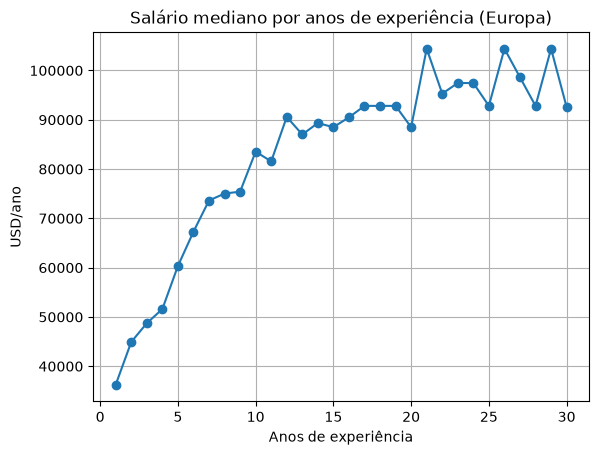

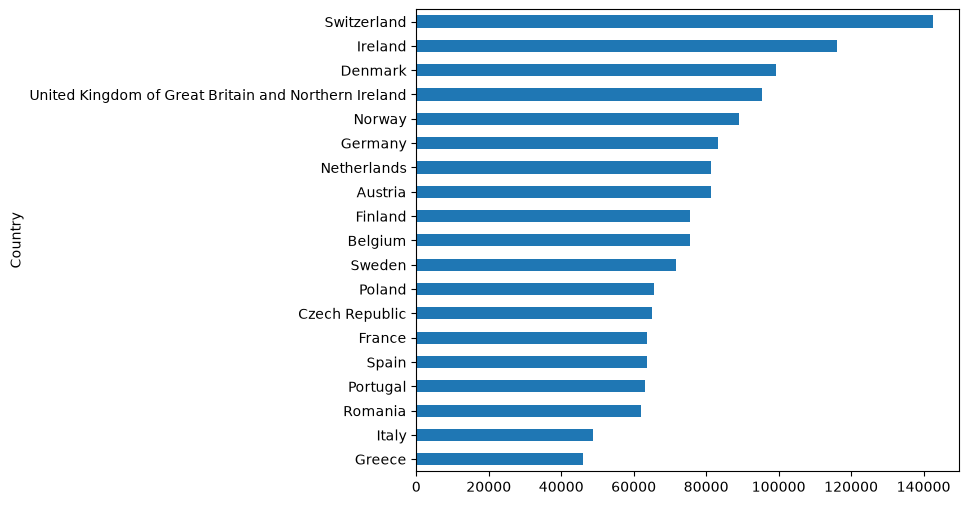

In [4]:
import matplotlib.pyplot as plt

europa = ["Portugal", "Spain", "France", "Germany", "Italy", "Netherlands", "Belgium",
          "Ireland", "Poland", "United Kingdom of Great Britain and Northern Ireland",
          "Sweden", "Switzerland", "Austria", "Denmark", "Norway", "Finland",
          "Czech Republic", "Romania", "Greece"]
eu = dados[dados["Country"].isin(europa)]
print("Europa:", len(eu))

med = eu.groupby("WorkExp")["ConvertedCompYearly"].median()
med[med.index <= 30].plot(marker="o", title="Salário mediano por anos de experiência (Europa)")
plt.xlabel("Anos de experiência"); plt.ylabel("USD/ano"); plt.grid(True)
plt.show()

eu.groupby("Country")["ConvertedCompYearly"].median().sort_values().plot(kind="barh", figsize=(7, 6))
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

X = eu[["Country", "WorkExp", "EdLevel", "RemoteWork"]].copy()
X["EdLevel"] = X["EdLevel"].fillna("Desconhecido")
X["RemoteWork"] = X["RemoteWork"].fillna("Desconhecido")

langs = ["Python", "JavaScript", "TypeScript", "Java", "C#", "SQL", "Go", "Rust", "PHP"]
for lang in langs:
    X[lang] = eu["LanguageHaveWorkedWith"].fillna("").str.split(";").apply(lambda l: int(lang in l))

y = eu["ConvertedCompYearly"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["Country", "EdLevel", "RemoteWork"]),
], remainder="passthrough")

for nome, modelo in [("Linear", LinearRegression()),
                     ("Random Forest", RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1))]:
    pipe = Pipeline([("prep", prep), ("modelo", modelo)])
    pipe.fit(X_train, y_train)
    erro = mean_absolute_error(y_test, pipe.predict(X_test))
    print(f"{nome}: erro médio de {erro:,.0f} $/ano")

Linear: erro médio de 28,364 $/ano
Random Forest: erro médio de 27,415 $/ano


In [6]:
import numpy as np
from sklearn.compose import TransformedTargetRegressor

X["DevType"] = eu["DevType"].fillna("Desconhecido")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

base = mean_absolute_error(y_test, np.full(len(y_test), y_train.median()))
print(f"Base (prever sempre a mediana): {base:,.0f} $/ano")

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), ["Country", "EdLevel", "RemoteWork", "DevType"]),
], remainder="passthrough")

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
modelo = TransformedTargetRegressor(regressor=Pipeline([("prep", prep), ("rf", rf)]),
                                    func=np.log, inverse_func=np.exp)
modelo.fit(X_train, y_train)
print(f"Random Forest melhorada: {mean_absolute_error(y_test, modelo.predict(X_test)):,.0f} $/ano")

Base (prever sempre a mediana): 34,726 $/ano
Random Forest melhorada: 26,390 $/ano


In [7]:
eu_pedro = pd.DataFrame([{
    "Country": "Portugal",
    "WorkExp": 2,
    "EdLevel": "Bachelor’s degree (B.A., B.S., B.Eng., etc.)",
    "RemoteWork": "Desconhecido",
    "DevType": "Developer, full-stack",
    **{lang: 0 for lang in langs},
}])
for lang in ["JavaScript", "TypeScript", "Python", "Java", "SQL"]:
    eu_pedro[lang] = 1

for anos in [1, 2, 5, 10]:
    eu_pedro["WorkExp"] = anos
    print(f"{anos} anos: {modelo.predict(eu_pedro)[0]:,.0f} $/ano")

1 anos: 31,569 $/ano
2 anos: 32,059 $/ano
5 anos: 62,180 $/ano
10 anos: 76,731 $/ano


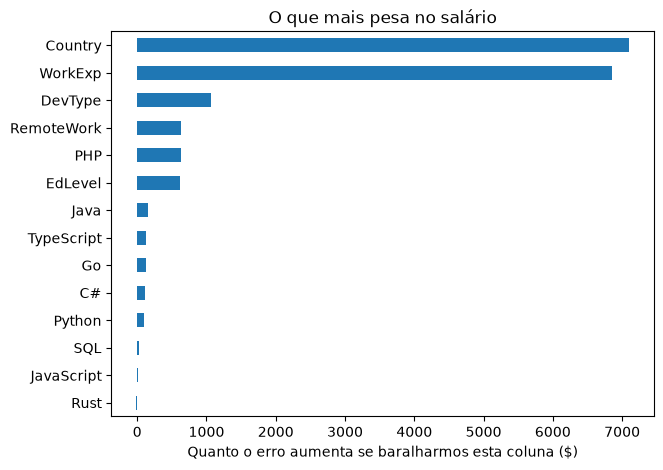

In [8]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(modelo, X_test, y_test, n_repeats=5,
                             random_state=42, scoring="neg_mean_absolute_error", n_jobs=-1)
pd.Series(imp.importances_mean, index=X_test.columns).sort_values().plot(
    kind="barh", figsize=(7, 5), title="O que mais pesa no salário")
plt.xlabel("Quanto o erro aumenta se baralharmos esta coluna ($)")
plt.show()

In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor

prep_gb = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False),
      ["Country", "EdLevel", "RemoteWork", "DevType"])],
    remainder="passthrough",
)

gb = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", prep_gb),
        ("gb", HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42)),
    ]),
    func=np.log, inverse_func=np.exp,
)

gb.fit(X_train, y_train)
erro_gb = mean_absolute_error(y_test, gb.predict(X_test))
print(f"Random Forest:      26,390 $")
print(f"Gradient Boosting:  {erro_gb:,.0f} $")

Random Forest:      26,390 $
Gradient Boosting:  25,752 $
